# Khai phá luật kết hợp và phân lớp `attack_type`

Notebook này dự đoán **14 loại lưu lượng** thay vì nhãn attack/benign. Kế thừa dữ liệu đã gộp và cách làm sạch `iat_min` của `01_eda_preprocess.ipynb`, nhưng chia lại theo `flow_id` **trước** khi tính ngưỡng rời rạc hóa hay huấn luyện. Không dùng các pickle feature đã chọn theo nhãn nhị phân ở phép chia cũ; notebook mới dùng lại các cột số gốc và chỉ xử lý chúng trên train mới. Một luồng chỉ thuộc train hoặc test. Không dùng `source_day`, định danh, địa chỉ, cổng và thời gian làm feature.

Accuracy có thể cao vì lớp `benign` chiếm đa số. Vì vậy, kết quả chính gồm **Macro F1, Balanced Accuracy và Recall từng lớp**. Với lớp chỉ có một `flow_id`, không thể vừa giữ luồng tách biệt vừa có mẫu ở cả train và test; bảng kết quả ghi rõ lớp nào không có mẫu test.

# Import

In [1]:
from collections import Counter, defaultdict
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, f1_score,
    precision_recall_fscore_support, confusion_matrix,
)
from IPython.display import display

RANDOM_STATE = 42
OUT_DIR = Path("04_output/03_association_classification_attack_type")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Đọc và làm sạch dữ liệu

In [2]:
raw_path = Path("02_merge_data/data_raw.csv")
all_columns = pd.read_csv(raw_path, nrows=0).columns.tolist()

# Theo notebook 01: bỏ cột định danh, cổng, thời gian và nhãn khỏi feature.
# Bỏ thêm source_day để mô hình không dựa vào ngày thu thập.
exclude_cols = {
    "flow_id", "src_addr", "dst_addr", "src_port", "dst_port",
    "timestamp", "source_day", "label",
}
feature_cols = [col for col in all_columns if col not in exclude_cols]
dtype_map = {col: "float32" for col in feature_cols}

df = pd.read_csv(
    raw_path, usecols=["flow_id", "label", *feature_cols],
    dtype=dtype_map,
)
df = df.rename(columns={"label": "attack_type"})
df["attack_type"] = df["attack_type"].str.lower()

# Notebook 01 đã xác định các dòng iat_min âm là bất hợp lý và loại chúng.
df = df[df["iat_min"].ge(0)].copy()
print("Dữ liệu sau làm sạch:", df.shape)
print("Số thuộc tính đầu vào:", len(feature_cols))

Dữ liệu sau làm sạch: (1835228, 78)
Số thuộc tính đầu vào: 76


In [3]:
class_table = df["attack_type"].value_counts().rename_axis("attack_type").reset_index(name="Số dòng")
class_table["Tỷ lệ (%)"] = (class_table["Số dòng"] / len(df) * 100).round(3)
display(class_table)

,attack_type,Số dòng,Tỷ lệ (%)
0,benign,1393615,75.937
1,portscan,160106,8.724
2,dos_hulk,158837,8.655
3,ddos,95637,5.211
4,dos_goldeneye,6761,0.368
5,dos_slowloris,5674,0.309
6,dos_slowhttptest,4866,0.265
7,ftp_patator,4000,0.218
8,ssh_patator,2957,0.161
9,webattack_bruteforce,1360,0.074


# Chia train/test theo luồng

In [4]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_pos, test_pos = next(splitter.split(df, groups=df["flow_id"]))
train_idx = df.index[train_pos]
test_idx = df.index[test_pos]
y_train = df.loc[train_idx, "attack_type"]
y_test = df.loc[test_idx, "attack_type"]

print(f"Train: {len(train_idx):,} | Test: {len(test_idx):,}")
print("Tỷ lệ test:", round(len(test_idx) / len(df) * 100, 2), "%")
print("Số flow_id trùng giữa train/test:",
      len(set(df.loc[train_idx, "flow_id"]) & set(df.loc[test_idx, "flow_id"])))

class_split = pd.DataFrame({
    "Train": y_train.value_counts(),
    "Test": y_test.value_counts(),
}).fillna(0).astype(int)
display(class_split)

Train: 1,464,101 | Test: 371,127
Tỷ lệ test: 20.22 %
Số flow_id trùng giữa train/test: 0


,Train,Test
attack_type,,
benign,1110497,283118
bot,591,144
ddos,76415,19222
dos_goldeneye,5445,1316
dos_hulk,127425,31412
dos_slowhttptest,3913,953
dos_slowloris,4573,1101
ftp_patator,3168,832
heartbleed,7,0


## Chuẩn bị dữ liệu phân lớp

Lấy tối đa 120.000 dòng train để các mô hình chạy được trên máy cá nhân. Các lớp có dưới 30 dòng được giữ toàn bộ trong train mẫu. Giá trị điền thiếu và cột có biến thiên đều được xác định từ **train mẫu**; test chỉ được biến đổi theo các giá trị đó.

In [5]:
MODEL_TRAIN_SIZE = 120_000
rare_classes = y_train.value_counts()[lambda counts: counts < 30].index
rare_idx = y_train[y_train.isin(rare_classes)].index
pool_idx = train_idx.difference(rare_idx, sort=False)

if len(train_idx) > MODEL_TRAIN_SIZE:
    base_idx, _ = train_test_split(
        pool_idx, train_size=MODEL_TRAIN_SIZE - len(rare_idx),
        stratify=y_train.loc[pool_idx], random_state=RANDOM_STATE,
    )
    model_idx = pd.Index(np.concatenate([base_idx, rare_idx]))
else:
    model_idx = train_idx

y_train_fit = y_train.loc[model_idx]
X_train_d0 = df.loc[model_idx, feature_cols].copy()
X_test_d0 = df.loc[test_idx, feature_cols].copy()

fill_values = X_train_d0.median().fillna(0)
X_train_d0 = X_train_d0.fillna(fill_values)
X_test_d0 = X_test_d0.fillna(fill_values)
used_features = [col for col in feature_cols if X_train_d0[col].nunique() > 1]
X_train_d0 = X_train_d0[used_features]
X_test_d0 = X_test_d0[used_features]

print("D0 train/test:", X_train_d0.shape, X_test_d0.shape)
print("Số lớp trong train mẫu:", y_train_fit.nunique())

D0 train/test: (120000, 73) (371127, 73)
Số lớp trong train mẫu: 14


# Khai phá luật kết hợp

## Rời rạc hóa giao dịch

Dùng cùng một nhóm thuộc tính mạng cho ba phương pháp. Ngưỡng tứ phân vị được học trên **train theo luồng** và áp dụng cho test. Mỗi giao dịch trong mẫu khai phá gồm các item thuộc tính và một item `class=attack_type`.

In [6]:
ARM_COLS = [
    "bwd_pkt_len_mean", "pkt_len_max", "flag_ack", "bytes_per_s",
    "flag_SYN", "ip_prot", "iat_max",
]
arm_train = pd.DataFrame(index=train_idx)
arm_test = pd.DataFrame(index=test_idx)
bin_edges = {}

for col in ARM_COLS:
    if col == "ip_prot":
        arm_train[col] = pd.Categorical(col + "=" + df.loc[train_idx, col].astype(str))
        arm_test[col] = pd.Categorical(col + "=" + df.loc[test_idx, col].astype(str))
        continue

    edges = np.unique(df.loc[train_idx, col].quantile([0, .25, .50, .75, 1]).to_numpy())
    if len(edges) == 1:
        item = f"{col}=constant"
        arm_train[col] = pd.Categorical([item] * len(train_idx))
        arm_test[col] = pd.Categorical([item] * len(test_idx))
        bin_edges[col] = edges
        continue

    edges[0] = -np.inf
    edges[-1] = np.inf
    bin_edges[col] = edges
    labels = [f"{col}=Q{i + 1}" for i in range(len(edges) - 1)]
    arm_train[col] = pd.cut(df.loc[train_idx, col], bins=edges,
                            labels=labels, include_lowest=True)
    arm_test[col] = pd.cut(df.loc[test_idx, col], bins=edges,
                           labels=labels, include_lowest=True)

print("Bảng item train/test:", arm_train.shape, arm_test.shape)

Bảng item train/test: (1464101, 7) (371127, 7)


In [7]:
MINING_SIZE = 30_000
MIN_SUPPORT = 0.01
MIN_CONFIDENCE = 0.50

if len(train_idx) > MINING_SIZE:
    mining_idx, _ = train_test_split(
        train_idx, train_size=MINING_SIZE,
        stratify=y_train, random_state=RANDOM_STATE,
    )
else:
    mining_idx = train_idx

transactions = [
    frozenset([*items, "class=" + label])
    for items, label in zip(
        arm_train.loc[mining_idx].astype(str).itertuples(index=False, name=None),
        y_train.loc[mining_idx],
    )
]
MIN_COUNT = int(np.ceil(MIN_SUPPORT * len(transactions)))
print("Số giao dịch khai phá:", len(transactions), "| Min count:", MIN_COUNT)

Số giao dịch khai phá: 30000 | Min count: 300


## Apriori

In [8]:
def make_vertical(rows):
    vertical = defaultdict(set)
    for tid, row in enumerate(rows):
        for item in row:
            vertical[item].add(tid)
    return dict(vertical)


def matching_tids(items, vertical):
    sets = [vertical[item] for item in items]
    if not sets:
        return set()
    result = sets[0].copy()
    for tids in sets[1:]:
        result.intersection_update(tids)
    return result


def apriori(vertical, min_count, max_len=3):
    # Sinh ứng viên từ tập phổ biến ở mức trước, rồi tỉa bằng tính chất Apriori.
    level = {frozenset([item]): len(tids)
             for item, tids in vertical.items() if len(tids) >= min_count}
    frequent = level.copy()
    for size in range(2, max_len + 1):
        previous = set(level)
        candidates = set()
        for left, right in combinations(sorted(previous, key=lambda s: tuple(sorted(s))), 2):
            candidate = left | right
            if len(candidate) != size:
                continue
            if all(frozenset(part) in previous for part in combinations(candidate, size - 1)):
                candidates.add(candidate)
        level = {}
        for candidate in candidates:
            count = len(matching_tids(candidate, vertical))
            if count >= min_count:
                level[candidate] = count
        frequent.update(level)
        if not level:
            break
    return frequent


vertical = make_vertical(transactions)
sets_apriori = apriori(vertical, MIN_COUNT)
print("Số tập mục phổ biến Apriori:", len(sets_apriori))

Số tập mục phổ biến Apriori: 1021


## FP-Growth

In [9]:
class FPNode:
    def __init__(self, item=None, count=0, parent=None):
        self.item = item
        self.count = count
        self.parent = parent
        self.children = {}


def build_fp_tree(weighted_rows, min_count):
    counts = Counter()
    for row, weight in weighted_rows:
        for item in row:
            counts[item] += weight
    frequent = {item: n for item, n in counts.items() if n >= min_count}
    root = FPNode()
    header = defaultdict(list)

    for row, weight in weighted_rows:
        ordered = sorted((item for item in row if item in frequent),
                         key=lambda item: (-frequent[item], item))
        node = root
        for item in ordered:
            if item not in node.children:
                node.children[item] = FPNode(item, parent=node)
                header[item].append(node.children[item])
            node = node.children[item]
            node.count += weight
    return header, frequent


def fp_growth(rows, min_count, max_len=3):
    frequent_sets = {}

    def mine(weighted_rows, prefix):
        header, counts = build_fp_tree(weighted_rows, min_count)
        for item in sorted(counts, key=lambda key: (counts[key], key)):
            pattern = prefix | {item}
            frequent_sets[frozenset(pattern)] = counts[item]
            if len(pattern) == max_len:
                continue
            conditional = []
            for node in header[item]:
                path = []
                parent = node.parent
                while parent is not None and parent.item is not None:
                    path.append(parent.item)
                    parent = parent.parent
                if path:
                    conditional.append((frozenset(path), node.count))
            if conditional:
                mine(conditional, pattern)

    mine([(row, 1) for row in rows], frozenset())
    return frequent_sets


sets_fp = fp_growth(transactions, MIN_COUNT)
print("Số tập mục phổ biến FP-Growth:", len(sets_fp))
print("Hai thuật toán cho cùng tập mục và support:", sets_apriori == sets_fp)

Số tập mục phổ biến FP-Growth: 1021
Hai thuật toán cho cùng tập mục và support: True


## CHARM

In [10]:
def charm_closed(vertical, min_count, max_prefix_len=3):
    nodes = [
        (frozenset([item]), tids.copy())
        for item, tids in vertical.items()
        if len(tids) >= min_count
    ]
    closed = {}

    def extend(nodes):
        nodes.sort(key=lambda pair: (len(pair[1]), tuple(sorted(pair[0]))))
        i = 0
        while i < len(nodes):
            xi, ti = nodes[i]
            children = []
            j = i + 1
            while j < len(nodes):
                xj, tj = nodes[j]
                both = ti & tj
                if len(both) < min_count:
                    j += 1
                    continue

                merged = xi | xj
                if ti == tj:
                    # Hai tập xuất hiện trên đúng cùng giao dịch.
                    xi = merged
                    children = [(x | xj, t) for x, t in children]
                    nodes.pop(j)
                elif ti < tj:
                    # Mọi giao dịch có xi cũng có xj.
                    xi = merged
                    children = [(x | xj, t) for x, t in children]
                    j += 1
                elif ti > tj:
                    if len(merged) <= max_prefix_len:
                        children.append((merged, both))
                    nodes.pop(j)
                else:
                    if len(merged) <= max_prefix_len:
                        children.append((merged, both))
                    j += 1

            closure = frozenset(xi | {
                item for item, tids in vertical.items() if ti <= tids
            })
            closed[closure] = len(ti)
            if children:
                extend(children)
            i += 1

    extend(nodes)
    return closed


sets_charm = charm_closed(vertical, MIN_COUNT, max_prefix_len=len(ARM_COLS) + 1)
print("Số tập mục đóng CHARM:", len(sets_charm))

Số tập mục đóng CHARM: 1340


## Chọn 3 luật cho mỗi phương pháp

Chỉ xét luật có kết luận là **một loại attack**, không chọn `benign`. Ưu tiên ba kết luận khác nhau nếu có đủ luật; trong các luật hợp lệ, chọn theo độ phủ tăng thêm, dùng confidence/lift để phá hòa. CHARM trả tập mục đóng; từ đó lấy lại các luật ngắn có cùng support để so sánh trên cùng phạm vi 1–2 điều kiện.
Apriori, FP-Growth và CHARM có thể cho cùng ba luật và coverage khi dùng cùng giao dịch, cùng ngưỡng và cùng cách chọn luật; đây là kết quả hợp lệ.


In [ ]:
def project_closed_rules(closed_sets, vertical, min_count):
    patterns = {}
    for closed in closed_sets:
        class_items = [item for item in closed if item.startswith("class=") and item != "class=benign"]
        feature_items = [item for item in closed if not item.startswith("class=")]
        for consequent in class_items:
            for size in [1, 2]:
                for antecedent in combinations(feature_items, size):
                    pattern = frozenset(antecedent) | {consequent}
                    count = len(matching_tids(pattern, vertical))
                    if count >= min_count:
                        patterns[pattern] = count
    return patterns


def candidate_rules(itemsets, vertical, n):
    rows = []
    for pattern, count in itemsets.items():
        class_items = [item for item in pattern if item.startswith("class=")]
        if len(class_items) != 1 or class_items[0] == "class=benign":
            continue
        consequent = class_items[0]
        antecedent = pattern - {consequent}
        if not 1 <= len(antecedent) <= 2:
            continue
        tids = matching_tids(antecedent, vertical)
        confidence = count / len(tids)
        base_rate = len(vertical[consequent]) / n
        lift = confidence / base_rate
        if confidence >= MIN_CONFIDENCE and lift > 1:
            rows.append({
                "antecedent": antecedent, "consequent": consequent,
                "tids": tids, "confidence": confidence, "lift": lift,
            })
    return rows


def select_three(candidates):
    selected = []
    covered = set()
    remaining = candidates.copy()
    while remaining and len(selected) < 3:
        unused = [row for row in remaining
                  if row["consequent"] not in {r["consequent"] for r in selected}]
        choices = unused if unused else remaining
        best = max(choices, key=lambda row: (
            len(row["tids"] - covered),
            row["confidence"], row["lift"], row["consequent"],
            tuple(sorted(row["antecedent"])),
        ))
        selected.append(best)
        covered.update(best["tids"])
        remaining.remove(best)
    if len(selected) < 3:
        raise ValueError("Chưa có đủ 3 luật; giảm MIN_SUPPORT hoặc MIN_CONFIDENCE rồi chạy lại trên train.")
    return selected


sets_charm_rules = project_closed_rules(sets_charm, vertical, MIN_COUNT)
rules_apriori = select_three(candidate_rules(sets_apriori, vertical, len(transactions)))
rules_fp = select_three(candidate_rules(sets_fp, vertical, len(transactions)))
rules_charm = select_three(candidate_rules(sets_charm_rules, vertical, len(transactions)))
print("Số luật ứng viên Apriori/FP-Growth/CHARM:",
      *[len(candidate_rules(sets, vertical, len(transactions)))
        for sets in [sets_apriori, sets_fp, sets_charm_rules]])

In [12]:
def rule_flags(items, rules):
    flags = pd.DataFrame(index=items.index)
    for i, rule in enumerate(rules, 1):
        match = pd.Series(True, index=items.index)
        for item in rule["antecedent"]:
            col = item.split("=", 1)[0]
            match &= items[col].astype(str).eq(item)
        flags[f"Rule_{i}"] = match.astype("int8")
    return flags


def describe_rules(rules, method):
    flags = rule_flags(arm_train, rules)
    rows = []
    for i, rule in enumerate(rules, 1):
        consequent = rule["consequent"].split("=", 1)[1]
        mask = flags[f"Rule_{i}"].astype(bool)
        coverage = mask.mean()
        support = (mask & y_train.eq(consequent)).mean()
        confidence = support / coverage if coverage else 0
        rows.append({
            "Phương pháp": method, "Luật": f"Rule_{i}",
            "Tiền đề": " & ".join(sorted(rule["antecedent"])),
            "Kết luận": consequent, "Coverage": coverage,
            "Support": support, "Confidence": confidence,
            "Lift": confidence / y_train.eq(consequent).mean(),
        })
    return pd.DataFrame(rows), flags


table_apriori, flags_apriori = describe_rules(rules_apriori, "Apriori")
table_fp, flags_fp = describe_rules(rules_fp, "FP-Growth")
table_charm, flags_charm = describe_rules(rules_charm, "CHARM")
rules_table = pd.concat([table_apriori, table_fp, table_charm], ignore_index=True)
display(rules_table.round(4))
rules_table.to_csv(OUT_DIR / "association_rules.csv", index=False)

Phương pháp,Luật,Tiền đề,Kết luận,Coverage,Support,Confidence,Lift
Apriori,Rule_1,bwd_pkt_len_mean=Q1 & ip_prot=6.0,portscan,0.1668,0.0874,0.5239,5.9903
Apriori,Rule_2,flag_ack=Q2 & pkt_len_max=Q4,dos_hulk,0.1208,0.0658,0.5442,6.2526
Apriori,Rule_3,bytes_per_s=Q3 & iat_max=Q4,ddos,0.0166,0.0119,0.7198,13.7909
FP-Growth,Rule_1,bwd_pkt_len_mean=Q1 & ip_prot=6.0,portscan,0.1668,0.0874,0.5239,5.9903
FP-Growth,Rule_2,flag_ack=Q2 & pkt_len_max=Q4,dos_hulk,0.1208,0.0658,0.5442,6.2526
FP-Growth,Rule_3,bytes_per_s=Q3 & iat_max=Q4,ddos,0.0166,0.0119,0.7198,13.7909
CHARM,Rule_1,bwd_pkt_len_mean=Q1 & ip_prot=6.0,portscan,0.1668,0.0874,0.5239,5.9903
CHARM,Rule_2,flag_ack=Q2 & pkt_len_max=Q4,dos_hulk,0.1208,0.0658,0.5442,6.2526
CHARM,Rule_3,bytes_per_s=Q3 & iat_max=Q4,ddos,0.0166,0.0119,0.7198,13.7909


## Truy vết từng lượt chọn luật

Chọn luật phủ thêm nhiều giao dịch train nhất. Confidence và lift chỉ dùng để phá hòa; bảng ghi độ phủ tăng thêm và độ phủ chung sau mỗi lượt.


In [ ]:
trace_rows = []
for method, rules in [
    ("Apriori", rules_apriori),
    ("FP-Growth", rules_fp),
    ("CHARM", rules_charm),
]:
    covered = set()
    for turn, rule in enumerate(rules, 1):
        new_tids = rule["tids"] - covered
        covered.update(rule["tids"])
        consequent = rule.get("consequent", "attack").removeprefix("class=")
        trace_rows.append({
            "Phương pháp": method,
            "Lượt": turn,
            "Luật chọn": " & ".join(sorted(rule["antecedent"])) + " ⇒ " + consequent,
            "Phủ thêm (%)": 100 * len(new_tids) / len(transactions),
            "Phủ chung sau lượt (%)": 100 * len(covered) / len(transactions),
            "Confidence": rule["confidence"],
            "Lift": rule["lift"],
        })

selection_trace = pd.DataFrame(trace_rows)
display(selection_trace.round(3))
selection_trace.to_csv(OUT_DIR / "rule_selection_trace.csv", index=False)


Phương pháp,Lượt,Luật chọn,Phủ thêm (%),Phủ chung sau lượt (%),Confidence,Lift
Apriori,1,bwd_pkt_len_mean=Q1 & ip_prot=6.0 ⇒ portscan,16.560,16.560,0.528,6.036
Apriori,2,flag_ack=Q2 & pkt_len_max=Q4 ⇒ dos_hulk,11.993,28.553,0.536,6.158
Apriori,3,bytes_per_s=Q3 & iat_max=Q4 ⇒ ddos,0.460,29.013,0.748,14.330
FP-Growth,1,bwd_pkt_len_mean=Q1 & ip_prot=6.0 ⇒ portscan,16.560,16.560,0.528,6.036
FP-Growth,2,flag_ack=Q2 & pkt_len_max=Q4 ⇒ dos_hulk,11.993,28.553,0.536,6.158
FP-Growth,3,bytes_per_s=Q3 & iat_max=Q4 ⇒ ddos,0.460,29.013,0.748,14.330
CHARM,1,bwd_pkt_len_mean=Q1 & ip_prot=6.0 ⇒ portscan,16.560,16.560,0.528,6.036
CHARM,2,flag_ack=Q2 & pkt_len_max=Q4 ⇒ dos_hulk,11.993,28.553,0.536,6.158
CHARM,3,bytes_per_s=Q3 & iat_max=Q4 ⇒ ddos,0.460,29.013,0.748,14.330


## Bảng nội dung luật và đối chiếu ba phương pháp

Mỗi dòng viết rõ điều kiện và kết luận. Bảng đối chiếu đếm luật trùng theo cả tiền đề và kết luận; “cùng bộ” không phụ thuộc thứ tự Rule_1/2/3.

`Q1`–`Q4` là các nhóm tứ phân vị tạo từ train. `Rule_i=1` khi tiền đề đúng; không dùng kết luận thật để tạo cột này.


In [13]:
rule_expressions = rules_table[["Phương pháp", "Luật", "Tiền đề", "Kết luận"]].copy()
rule_expressions["Luật kết hợp"] = (
    rule_expressions["Tiền đề"] + " ⇒ " + rule_expressions["Kết luận"]
)
rule_expressions = rule_expressions[["Phương pháp", "Luật", "Luật kết hợp"]]
display(rule_expressions)
rule_expressions.to_csv(OUT_DIR / "rule_expressions.csv", index=False)


Phương pháp,Luật,Luật kết hợp
Apriori,Rule_1,bwd_pkt_len_mean=Q1 & ip_prot=6.0 ⇒ portscan
Apriori,Rule_2,flag_ack=Q2 & pkt_len_max=Q4 ⇒ dos_hulk
Apriori,Rule_3,bytes_per_s=Q3 & iat_max=Q4 ⇒ ddos
FP-Growth,Rule_1,bwd_pkt_len_mean=Q1 & ip_prot=6.0 ⇒ portscan
FP-Growth,Rule_2,flag_ack=Q2 & pkt_len_max=Q4 ⇒ dos_hulk
FP-Growth,Rule_3,bytes_per_s=Q3 & iat_max=Q4 ⇒ ddos
CHARM,Rule_1,bwd_pkt_len_mean=Q1 & ip_prot=6.0 ⇒ portscan
CHARM,Rule_2,flag_ack=Q2 & pkt_len_max=Q4 ⇒ dos_hulk
CHARM,Rule_3,bytes_per_s=Q3 & iat_max=Q4 ⇒ ddos


In [14]:
method_order = ["Apriori", "FP-Growth", "CHARM"]
method_rules = {}
for method in method_order:
    rows = rules_table.loc[
        rules_table["Phương pháp"] == method, ["Tiền đề", "Kết luận"]
    ]
    method_rules[method] = list(rows.itertuples(index=False, name=None))

comparison_rows = []
for left, right in combinations(method_order, 2):
    left_rules = method_rules[left]
    right_rules = method_rules[right]
    common = len(set(left_rules) & set(right_rules))
    comparison_rows.append({
        "So sánh": f"{left} / {right}",
        "Số luật trùng": f"{common}/3",
        "Cùng bộ 3 luật": "Có" if set(left_rules) == set(right_rules) else "Không",
        "Cùng thứ tự": "Có" if left_rules == right_rules else "Không",
    })

rule_comparison = pd.DataFrame(comparison_rows)
display(rule_comparison)
rule_comparison.to_csv(OUT_DIR / "rule_comparison.csv", index=False)


So sánh,Số luật trùng,Cùng bộ 3 luật,Cùng thứ tự
Apriori / FP-Growth,3/3,Có,Có
Apriori / CHARM,3/3,Có,Có
FP-Growth / CHARM,3/3,Có,Có


In [15]:
coverage_table = pd.DataFrame([
    {
        "Phương pháp": method,
        "Luật 1 (%)": 100 * flags["Rule_1"].mean(),
        "Luật 2 (%)": 100 * flags["Rule_2"].mean(),
        "Luật 3 (%)": 100 * flags["Rule_3"].mean(),
        "Độ phủ chung (%)": 100 * flags.any(axis=1).mean(),
    }
    for method, flags in [
        ("Apriori", flags_apriori),
        ("FP-Growth", flags_fp),
        ("CHARM", flags_charm),
    ]
])
display(coverage_table.round(2))
coverage_table.to_csv(OUT_DIR / "rule_coverage.csv", index=False)

Phương pháp,Luật 1 (%),Luật 2 (%),Luật 3 (%),Độ phủ chung (%)
Apriori,16.68,12.08,1.66,29.25
FP-Growth,16.68,12.08,1.66,29.25
CHARM,16.68,12.08,1.66,29.25


# Tạo D1 = D0 + 3 thuộc tính luật

In [16]:
rules_by_method = {
    "Apriori": rules_apriori,
    "FP-Growth": rules_fp,
    "CHARM": rules_charm,
}
chosen_method = coverage_table.sort_values(
    ["Độ phủ chung (%)", "Phương pháp"], ascending=[False, True]
).iloc[0]["Phương pháp"]
chosen_rules = rules_by_method[chosen_method]
print("Phương pháp dùng tạo thuộc tính:", chosen_method)

# Mỗi Rule_i chỉ kiểm tra tiền đề; không dùng attack_type thật để tạo feature.
train_flags = rule_flags(arm_train.loc[model_idx], chosen_rules)
test_flags = rule_flags(arm_test, chosen_rules)
X_train_d1 = X_train_d0.join(train_flags)
X_test_d1 = X_test_d0.join(test_flags)
print("D1 train/test:", X_train_d1.shape, X_test_d1.shape)


Phương pháp dùng tạo thuộc tính: Apriori
D1 train/test: (120000, 76) (371127, 76)


## Ba cột luật bổ sung lấy từ phương pháp đã chọn


In [17]:
selected_rule_map = rule_expressions.loc[
    rule_expressions["Phương pháp"] == chosen_method,
    ["Luật", "Luật kết hợp"],
].reset_index(drop=True)
display(selected_rule_map)
selected_rule_map.to_csv(OUT_DIR / "selected_rule_features.csv", index=False)


Luật,Luật kết hợp
Rule_1,bwd_pkt_len_mean=Q1 & ip_prot=6.0 ⇒ portscan
Rule_2,flag_ack=Q2 & pkt_len_max=Q4 ⇒ dos_hulk
Rule_3,bytes_per_s=Q3 & iat_max=Q4 ⇒ ddos


## Ví dụ D1: thuộc tính đã tiền xử lý và ba cột luật


In [18]:
# Hiển thị các cột gốc xuất hiện trong ba tiền đề, cạnh ba cột luật mới.
rule_cols = ["Rule_1", "Rule_2", "Rule_3"]
source_cols = sorted({
    item.split("=", 1)[0]
    for rule in chosen_rules
    for item in rule["antecedent"]
})
# Lấy vài dòng thỏa từng luật và vài dòng không thỏa luật nào.
example_idx = []
for col in rule_cols:
    example_idx.extend(X_train_d1.index[X_train_d1[col].eq(1)][:2])
example_idx.extend(X_train_d1.index[X_train_d1[rule_cols].eq(0).all(axis=1)][:2])
example_idx = list(dict.fromkeys(example_idx))
d1_example = X_train_d1.loc[example_idx, source_cols + rule_cols]
display(d1_example)
d1_example.to_csv(OUT_DIR / "d1_example.csv", index=True)


ID,bwd_pkt_len_mean,bytes_per_s,flag_ack,iat_max,ip_prot,pkt_len_max,Rule_1,Rule_2,Rule_3
640356,46.375000,17.411684,35.0,10027152.0,6.0,641.0,1,0,0
1066143,12.533333,32.754700,23.0,3053380.0,6.0,34.0,1,0,0
1499168,1932.500000,79997.040000,8.0,136278.0,6.0,4344.0,0,1,0
431127,2319.000000,86022.380000,7.0,133959.0,6.0,7300.0,0,1,0
464309,2319.000000,6636.866000,7.0,1748730.0,6.0,7215.0,0,1,1
472430,2319.000000,7102.976600,7.0,1620084.0,6.0,5840.0,0,1,1
818156,91.000000,2300.626200,0.0,60853.0,17.0,91.0,0,0,0
773603,48.000000,598130.800000,0.0,315.0,17.0,48.0,0,0,0


# Phân lớp `attack_type`

Hai mô hình chạy trên cùng train/test ở D0 và D1. Macro F1 và Balanced Accuracy cho mỗi loại hiện diện trong test trọng số ngang nhau; Accuracy và Weighted F1 vẫn được báo cáo để tham khảo. Lớp không có mẫu test không được tính vào Macro F1.

In [19]:
def build_models():
    return {
        "Decision Tree": DecisionTreeClassifier(
            max_depth=14, min_samples_leaf=5, random_state=RANDOM_STATE
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=80, max_depth=18, min_samples_leaf=5,
            n_jobs=-1, random_state=RANDOM_STATE,
        ),
    }


test_classes = sorted(y_test.unique())
results_rows = []
predictions = {}
for dataset, X_fit, X_eval in [
    ("D0", X_train_d0, X_test_d0),
    ("D1", X_train_d1, X_test_d1),
]:
    for name, model in build_models().items():
        print("Đang chạy:", dataset, name)
        model.fit(X_fit, y_train_fit)
        pred = model.predict(X_eval)
        predictions[(dataset, name)] = pred
        class_recall = precision_recall_fscore_support(
            y_test, pred, labels=test_classes, zero_division=0
        )[1]
        results_rows.append({
            "Bộ dữ liệu": dataset, "Mô hình": name,
            "Accuracy": accuracy_score(y_test, pred),
            "Macro F1": f1_score(y_test, pred, labels=test_classes,
                                  average="macro", zero_division=0),
            "Weighted F1": f1_score(y_test, pred, labels=test_classes,
                                     average="weighted", zero_division=0),
            "Balanced Accuracy": class_recall.mean(),
        })

results = pd.DataFrame(results_rows)
results_display = results.copy()
for col in ["Accuracy", "Macro F1", "Weighted F1", "Balanced Accuracy"]:
    results_display[col] = results_display[col].map(lambda value: f"{value * 100:.2f}%")
display(results_display)
results.to_csv(OUT_DIR / "classification_results.csv", index=False)

Đang chạy: D0 Decision Tree
Đang chạy: D0 Random Forest
Đang chạy: D1 Decision Tree
Đang chạy: D1 Random Forest


Bộ dữ liệu,Mô hình,Accuracy,Macro F1,Weighted F1,Balanced Accuracy
D0,Decision Tree,99.79%,80.70%,99.78%,81.73%
D0,Random Forest,99.84%,82.74%,99.84%,82.28%
D1,Decision Tree,99.79%,80.58%,99.78%,81.75%
D1,Random Forest,99.83%,82.19%,99.83%,81.79%


## Precision, Recall và F1 theo từng loại tấn công

In [20]:
class_rows = []
for dataset in ["D0", "D1"]:
    pred = predictions[(dataset, "Random Forest")]
    precision, recall, f1, support = precision_recall_fscore_support(
        y_test, pred, labels=sorted(y_train.unique()), zero_division=0
    )
    for label, p, r, f, n in zip(sorted(y_train.unique()), precision, recall, f1, support):
        class_rows.append({
            "Bộ dữ liệu": dataset, "attack_type": label,
            "Số mẫu test": int(n), "Precision": p if n else np.nan,
            "Recall": r if n else np.nan, "F1": f if n else np.nan,
        })

class_results = pd.DataFrame(class_rows)
class_display = class_results.copy()
for col in ["Precision", "Recall", "F1"]:
    class_display[col] = class_display[col].map(
        lambda value: "—" if pd.isna(value) else f"{value * 100:.1f}%"
    )
display(class_display)
class_results.to_csv(OUT_DIR / "per_class_results.csv", index=False)

Bộ dữ liệu,attack_type,Số mẫu test,Precision,Recall,F1
D0,benign,283118,99.9%,99.9%,99.9%
D0,bot,144,100.0%,86.1%,92.5%
D0,ddos,19222,100.0%,100.0%,100.0%
D0,dos_goldeneye,1316,90.1%,97.9%,93.9%
D0,dos_hulk,31412,100.0%,99.9%,100.0%
D0,dos_slowhttptest,953,92.8%,95.4%,94.1%
D0,dos_slowloris,1101,99.5%,98.5%,99.0%
D0,ftp_patator,832,100.0%,99.5%,99.8%
D0,heartbleed,0,—,—,—
D0,portscan,32054,99.9%,99.9%,99.9%


## Recall từng lớp của Random Forest

Biểu đồ cho thấy lớp nhỏ nào còn bị bỏ sót; `heartbleed` không xuất hiện vì tập test không có mẫu của lớp này.


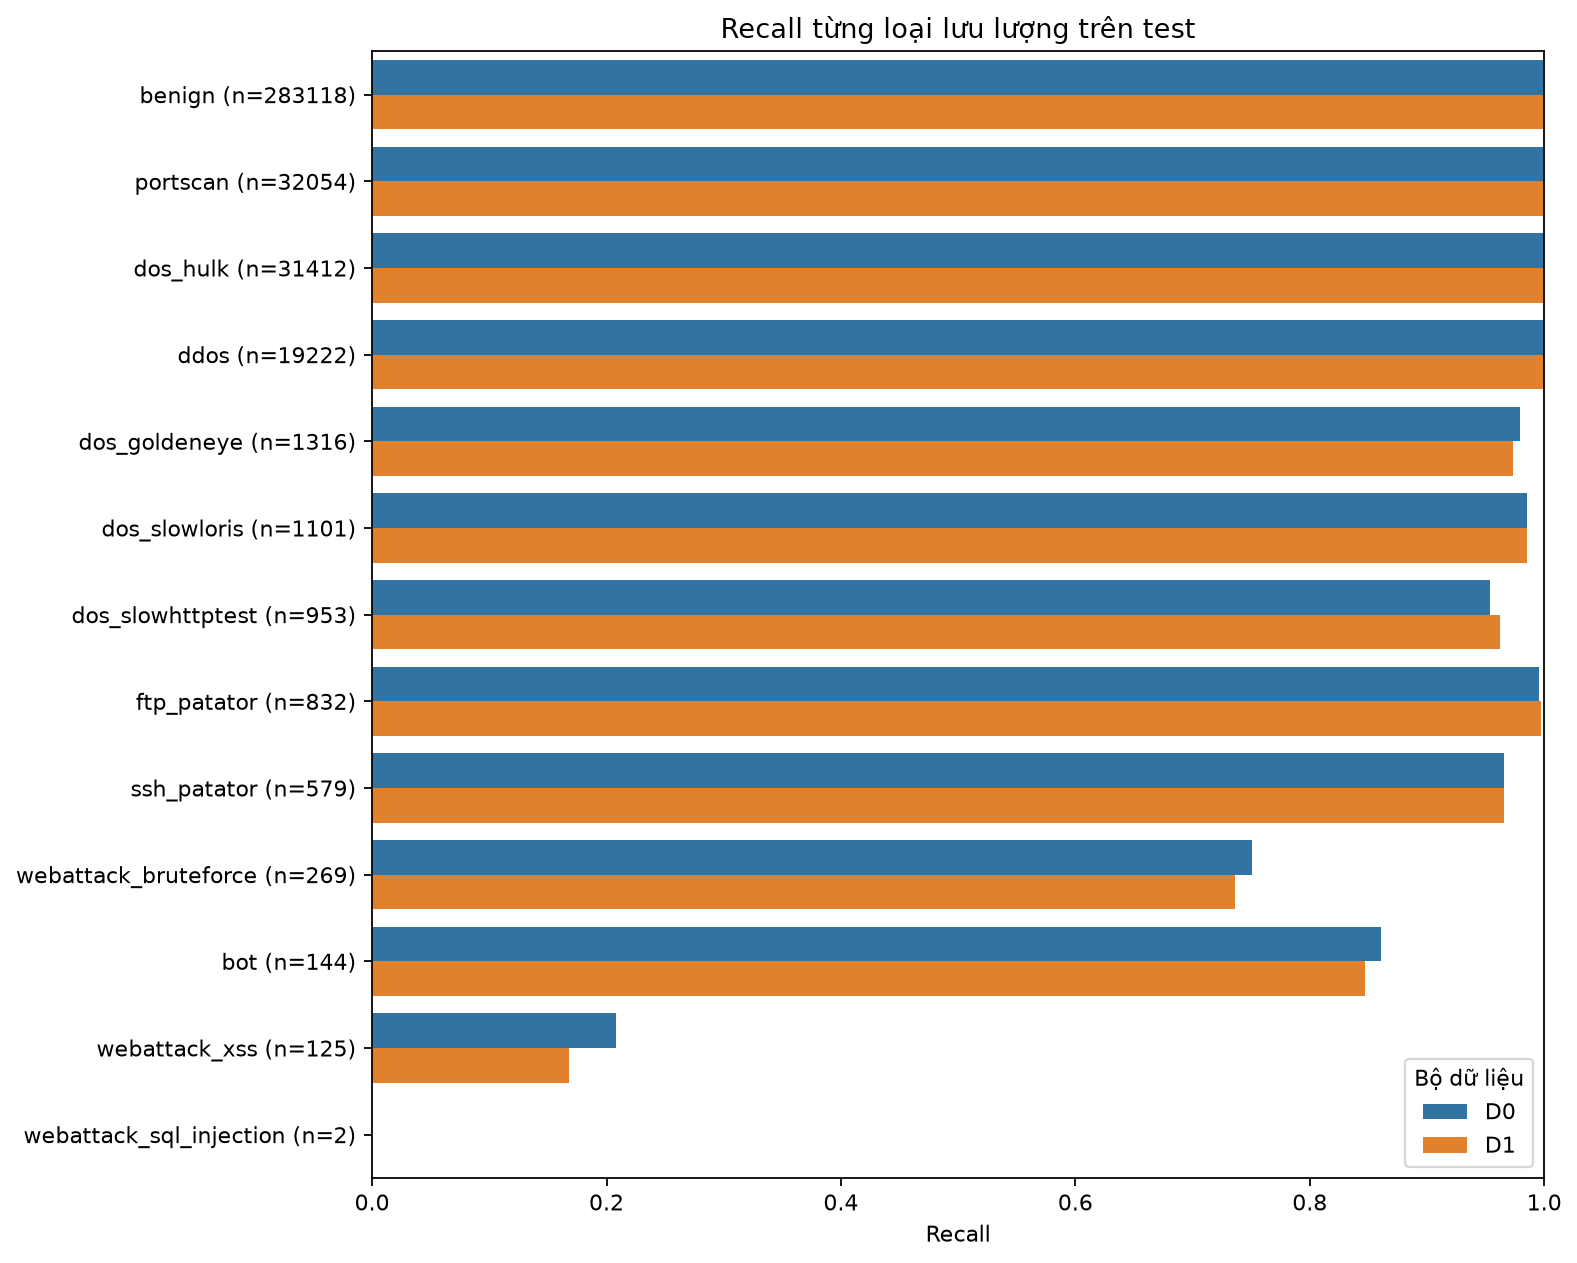

In [21]:
recall_plot = class_results[class_results["Số mẫu test"] > 0].copy()
recall_plot["Tên lớp"] = (
    recall_plot["attack_type"] + " (n=" + recall_plot["Số mẫu test"].astype(str) + ")"
)
order = recall_plot.loc[recall_plot["Bộ dữ liệu"] == "D0"].sort_values(
    "Số mẫu test", ascending=False
)["Tên lớp"].tolist()

fig, ax = plt.subplots(figsize=(10, 8))
sns.barplot(data=recall_plot, y="Tên lớp", x="Recall", hue="Bộ dữ liệu",
            order=order, ax=ax)
ax.set_xlim(0, 1)
ax.set_xlabel("Recall")
ax.set_ylabel("")
ax.set_title("Recall từng loại lưu lượng trên test")
plt.tight_layout()
plt.savefig(OUT_DIR / "per_class_recall.png", dpi=160, bbox_inches="tight")
plt.show()


## Confusion matrix của Random Forest

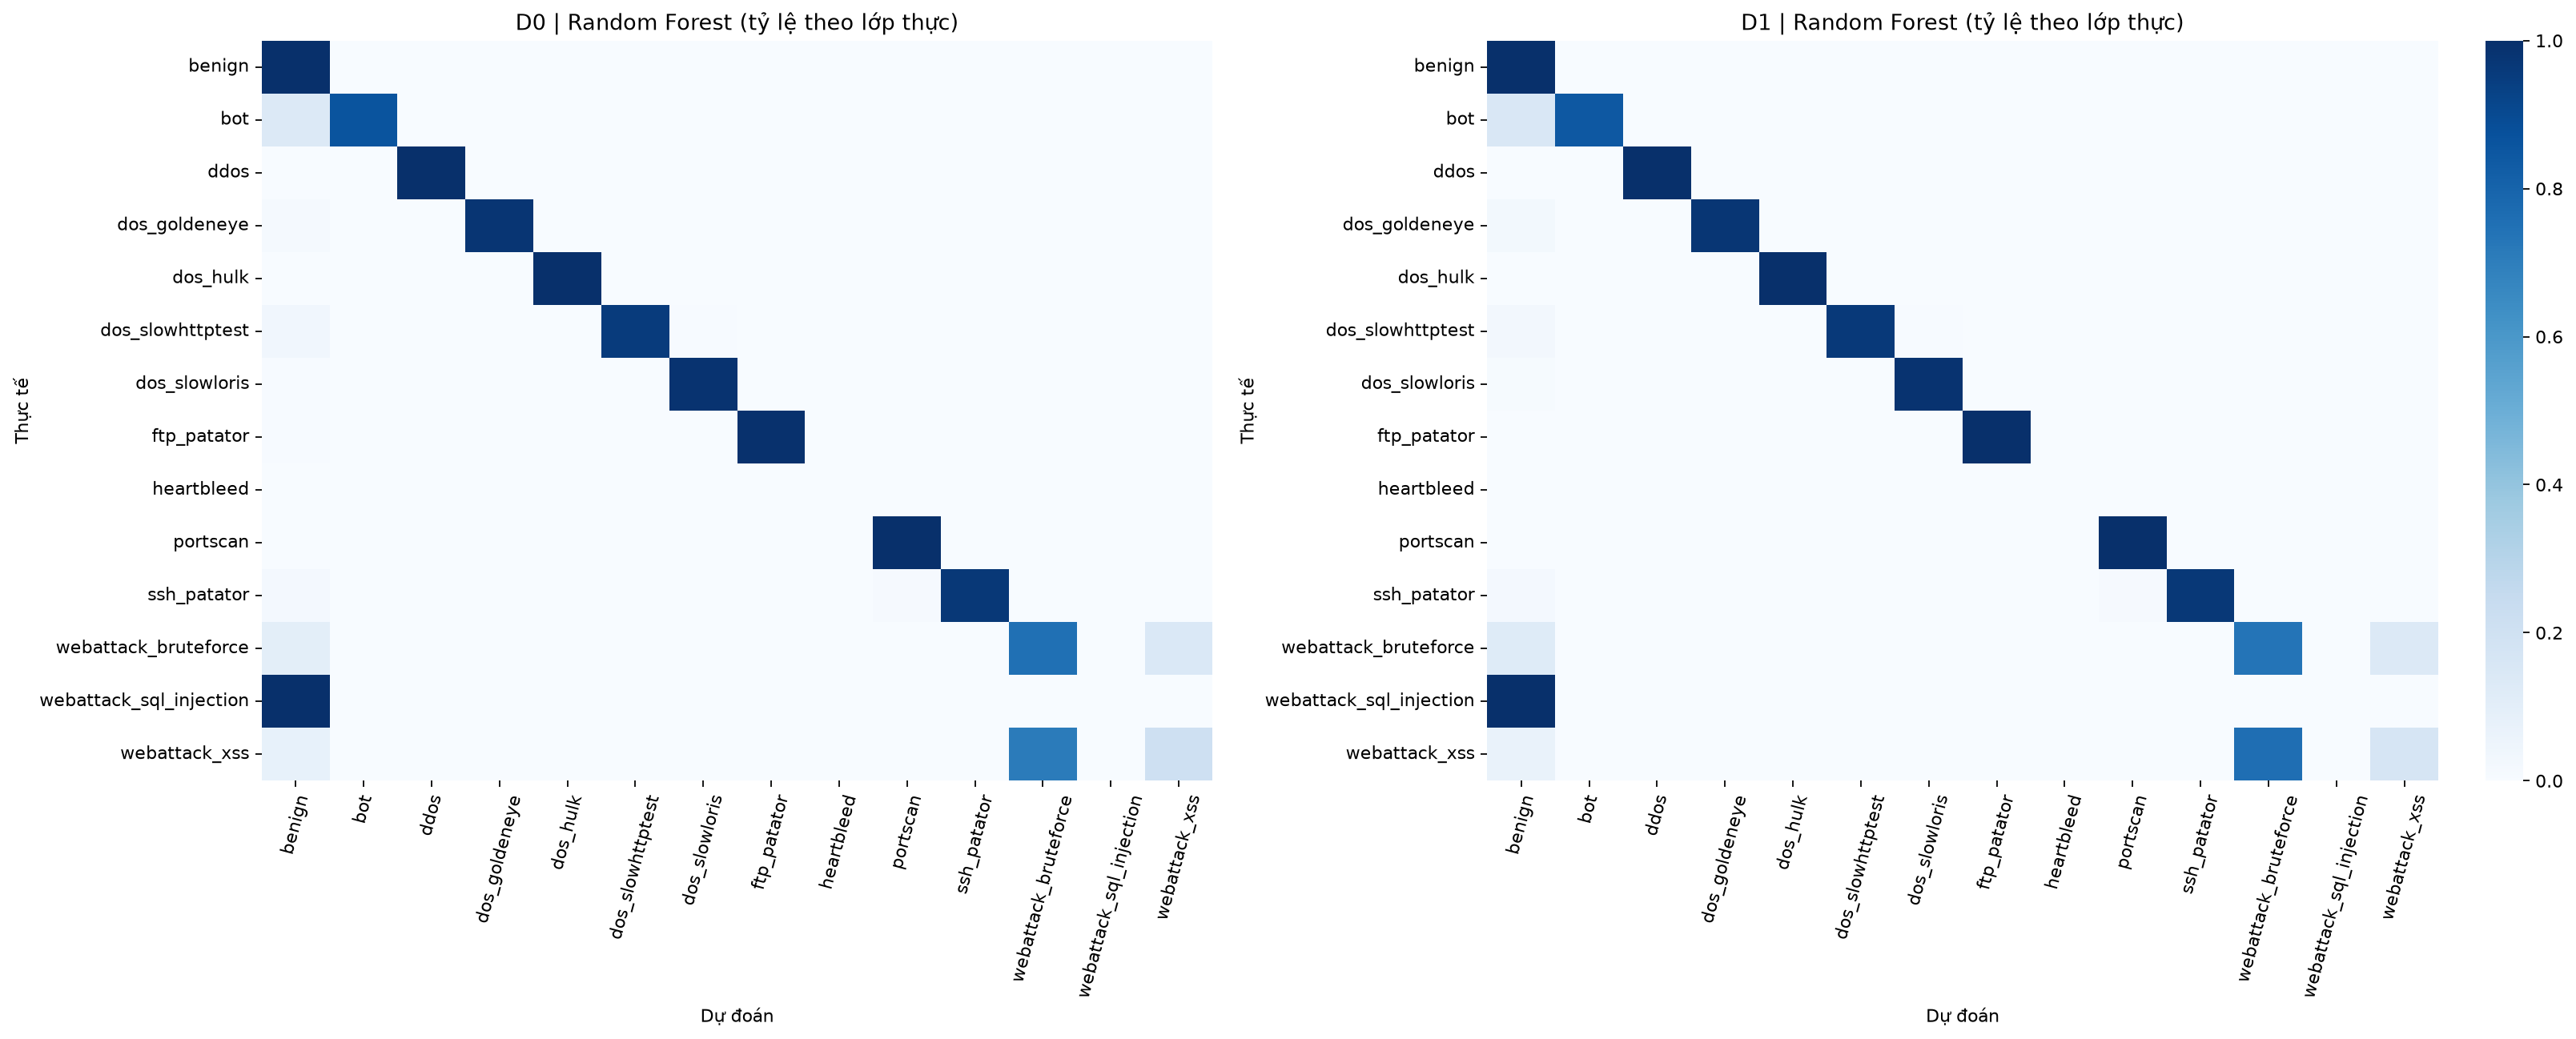

In [22]:
all_classes = sorted(set(y_train) | set(y_test))
fig, axes = plt.subplots(1, 2, figsize=(20, 8), constrained_layout=True)
for ax, dataset in zip(axes, ["D0", "D1"]):
    matrix = confusion_matrix(
        y_test, predictions[(dataset, "Random Forest")], labels=all_classes
    )
    row_total = matrix.sum(axis=1, keepdims=True)
    ratio = np.divide(matrix, row_total, out=np.zeros_like(matrix, dtype=float),
                      where=row_total != 0)
    sns.heatmap(
        ratio, cmap="Blues", vmin=0, vmax=1, ax=ax,
        xticklabels=all_classes, yticklabels=all_classes,
        cbar=(dataset == "D1"),
    )
    ax.set_title(f"{dataset} | Random Forest (tỷ lệ theo lớp thực)")
    ax.set_xlabel("Dự đoán")
    ax.set_ylabel("Thực tế")
    ax.tick_params(axis="x", rotation=75)
    ax.tick_params(axis="y", rotation=0)

plt.savefig(OUT_DIR / "confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()

## So sánh D0 và D1

In [23]:
model_order = results["Mô hình"].drop_duplicates().tolist()
d0 = results[results["Bộ dữ liệu"] == "D0"].set_index("Mô hình")
d1 = results[results["Bộ dữ liệu"] == "D1"].set_index("Mô hình")
metrics = ["Accuracy", "Macro F1", "Weighted F1", "Balanced Accuracy"]

effect = pd.DataFrame({"Mô hình": model_order})
for metric in metrics:
    effect[f"Δ {metric} (điểm %)"] = (
        d1.loc[model_order, metric].to_numpy()
        - d0.loc[model_order, metric].to_numpy()
    ) * 100

effect_display = effect.copy()
for col in effect.columns[1:]:
    effect_display[col] = effect_display[col].map(
        lambda value: "0.000" if abs(value) < .0005 else f"{value:+.3f}"
    )
display(effect_display)
effect.to_csv(OUT_DIR / "rule_feature_effect.csv", index=False)

Mô hình,Δ Accuracy (điểm %),Δ Macro F1 (điểm %),Δ Weighted F1 (điểm %),Δ Balanced Accuracy (điểm %)
Decision Tree,-0.002,-0.122,-0.001,+0.015
Random Forest,-0.009,-0.550,-0.010,-0.496


## Cách đọc kết quả

- **Accuracy** tính trên tất cả dòng test, nên lớp `benign` lớn có thể che kết quả kém của lớp hiếm.
- **Macro F1**, **Balanced Accuracy** và bảng Recall từng `attack_type` cho thấy mô hình có nhận ra các lớp tấn công nhỏ hay không.
- **Coverage** đánh giá phạm vi áp dụng tiền đề luật; các chỉ số phân lớp được tính riêng trên test.
- Vì dữ liệu chỉ có một nhóm `flow_id` cho `heartbleed`, phép chia theo luồng này không có mẫu `heartbleed` ở test. Không suy ra chất lượng dự đoán lớp đó từ bảng điểm hiện tại.